# Tech Challenge — Fase 2 | FIAP
## Classificação da qualidade de vinhos com Machine Learning

### 1. Introdução e objetivo

A qualidade de um vinho pode estar associada a diferentes características físico-químicas, como teor alcoólico, acidez, densidade e concentração de sulfatos.

Neste projeto, utilizamos o conjunto de dados *Wine Quality* para investigar essas relações e desenvolver modelos de Machine Learning capazes de classificar vinhos em duas categorias:

- **Classe 0 — Baixa ou média qualidade:** vinhos com nota inferior a 7.
- **Classe 1 — Alta qualidade:** vinhos com nota igual ou superior a 7.

O objetivo é comparar diferentes algoritmos de classificação, identificar características relevantes para as previsões e avaliar como os resultados podem apoiar decisões de uma vinícola.

### 2. Etapas do projeto

O trabalho foi organizado nas seguintes etapas:

1. Importação e exploração dos dados.
2. Análise da distribuição das notas e das características químicas.
3. Identificação e tratamento de registros duplicados.
4. Preparação dos dados e divisão em treinamento e teste.
5. Treinamento de modelos de classificação.
6. Avaliação e comparação dos resultados.
7. Interpretação das características químicas e recomendações de negócio.

### 3. Base de dados

O conjunto de dados original contém **1.143 registros**, com 11 características físico-químicas, a nota de qualidade e um identificador.

Durante a preparação, foram identificados e removidos **125 registros duplicados**, desconsiderando o identificador. Assim, a modelagem foi realizada com **1.018 registros**.

A variável de classificação foi criada a partir da nota original de qualidade, considerando como alta qualidade os vinhos com nota igual ou superior a 7.

In [1]:
print("Iniciando Tech Challenge FIAP - Fase 2")

Iniciando Tech Challenge FIAP - Fase 2


In [2]:
import pandas as pd

vinhos = pd.read_csv("WineQT.csv")

vinhos.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
vinhos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [4]:
vinhos["quality"].value_counts().sort_index()

,count
quality,
3,6
4,33
5,483
6,462
7,143
8,16


In [5]:
vinhos["alta_qualidade"] = (vinhos["quality"] >= 7).astype(int)

vinhos[["quality", "alta_qualidade"]].head(10)

,quality,alta_qualidade
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0


In [6]:
vinhos.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,alta_qualidade
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379,0.139108
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116,0.346210
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000,0.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000,0.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000,0.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000,1.000000


In [7]:
vinhos.groupby("alta_qualidade")[
    ["alcohol", "volatile acidity", "density", "sulphates"]
].mean().round(2)

,alcohol,volatile acidity,density,sulphates
alta_qualidade,,,,
0,10.27,0.55,1.0,0.64
1,11.53,0.40,1.0,0.75


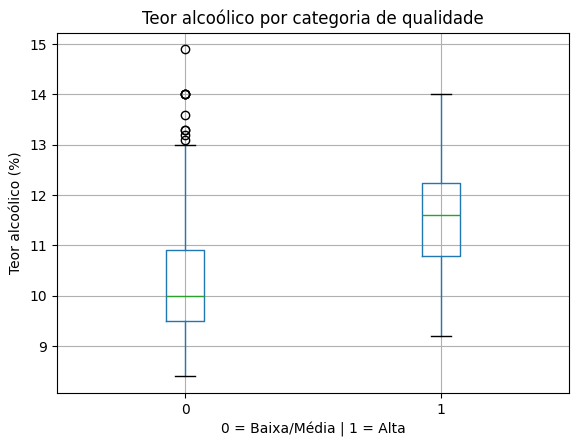

In [8]:
import matplotlib.pyplot as plt

vinhos.boxplot(column="alcohol", by="alta_qualidade")

plt.title("Teor alcoólico por categoria de qualidade")
plt.suptitle("")
plt.xlabel("0 = Baixa/Média | 1 = Alta")
plt.ylabel("Teor alcoólico (%)")
plt.show()

In [9]:
correlacoes = vinhos.corr(numeric_only=True)["alta_qualidade"]

correlacoes.sort_values(ascending=False)

,alta_qualidade
alta_qualidade,1.000000
quality,0.720433
alcohol,0.403676
citric acid,0.251146
sulphates,0.208020
fixed acidity,0.123212
residual sugar,0.064145
Id,0.019165
free sulfur dioxide,-0.055977
pH,-0.073318


In [10]:
vinhos.duplicated(subset=vinhos.columns.drop("Id")).sum()

np.int64(125)

In [11]:
vinhos = vinhos.drop_duplicates(
    subset=vinhos.columns.drop("Id")
)

print("Quantidade de vinhos após limpeza:", len(vinhos))

Quantidade de vinhos após limpeza: 1018


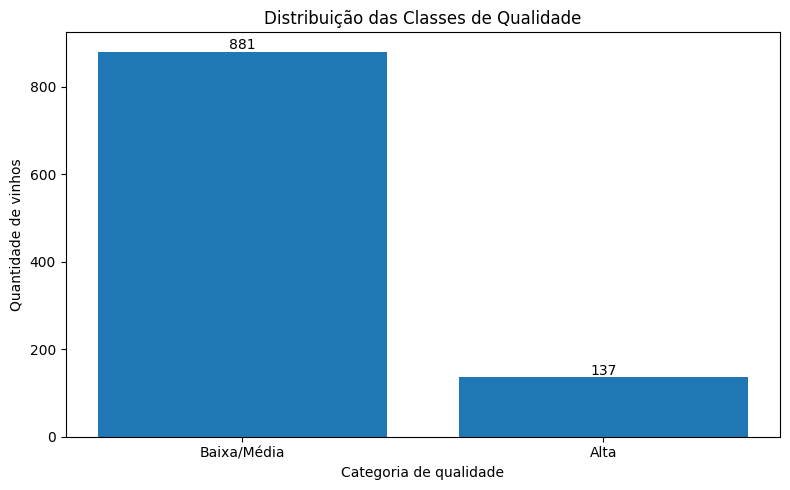

In [12]:
# Contar os vinhos de cada categoria
contagem = vinhos["alta_qualidade"].value_counts().sort_index()

# Criar o gráfico
plt.figure(figsize=(8, 5))

plt.bar(
    ["Baixa/Média", "Alta"],
    contagem.values
)

plt.title("Distribuição das Classes de Qualidade")
plt.xlabel("Categoria de qualidade")
plt.ylabel("Quantidade de vinhos")

# Mostrar os valores acima das barras
for i, valor in enumerate(contagem.values):
    plt.text(i, valor + 5, str(valor), ha="center")

plt.tight_layout()

# Salvar para a apresentação
plt.savefig("distribuicao_classes.png", dpi=300)

plt.show()

In [13]:
X = vinhos.drop(columns=["Id", "quality", "alta_qualidade"])

y = vinhos["alta_qualidade"]

print("Características:", X.shape)
print("Classificações:", y.shape)

Características: (1018, 11)
Classificações: (1018,)


In [14]:
# Selecionar apenas as características químicas
caracteristicas = X.columns

# Contar outliers em cada característica
for coluna in caracteristicas:
    Q1 = vinhos[coluna].quantile(0.25)
    Q3 = vinhos[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    quantidade = (
        (vinhos[coluna] < limite_inferior) |
        (vinhos[coluna] > limite_superior)
    ).sum()

    print(coluna, ":", quantidade, "outliers")

fixed acidity : 37 outliers
volatile acidity : 10 outliers
citric acid : 1 outliers
residual sugar : 95 outliers
chlorides : 71 outliers
free sulfur dioxide : 16 outliers
total sulfur dioxide : 33 outliers
density : 30 outliers
pH : 24 outliers
sulphates : 41 outliers
alcohol : 6 outliers


### Análise de valores extremos (outliers)

Foi utilizado o método do intervalo interquartil (IQR) para identificar valores potencialmente extremos nas 11 características físico-químicas.

As variáveis com maior quantidade de outliers foram açúcar residual (95), cloretos (71), sulfatos (41), acidez fixa (37) e dióxido de enxofre total (33).

Os valores extremos foram mantidos na base, pois podem representar características reais dos vinhos e não foram encontradas evidências suficientes para classificá-los como erros.

Essa decisão preserva a diversidade das observações, embora os valores extremos possam influenciar o comportamento de alguns algoritmos.

A contagem foi realizada individualmente por característica, portanto um mesmo vinho pode apresentar valores extremos em mais de uma variável.

In [15]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Vinhos para treinamento:", len(X_treino))
print("Vinhos para teste:", len(X_teste))
print("Distribuição das classes:")
print(y.value_counts())

Vinhos para treinamento: 814
Vinhos para teste: 204
Distribuição das classes:
alta_qualidade
0    881
1    137
Name: count, dtype: int64


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Padronizar as características
padronizador = StandardScaler()

X_treino_padronizado = padronizador.fit_transform(X_treino)
X_teste_padronizado = padronizador.transform(X_teste)

# Criar e treinar o modelo
modelo_logistico = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_logistico.fit(X_treino_padronizado, y_treino)

print("Primeiro modelo treinado com sucesso!")

Primeiro modelo treinado com sucesso!


In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Fazer previsões com os vinhos de teste
previsoes_logistica = modelo_logistico.predict(X_teste_padronizado)

# Calcular a acurácia
acuracia_logistica = accuracy_score(y_teste, previsoes_logistica)

print("Acurácia:", round(acuracia_logistica * 100, 2), "%")

print("\nRelatório de classificação:")
print(classification_report(y_teste, previsoes_logistica, zero_division=0))

print("\nMatriz de confusão:")
print(confusion_matrix(y_teste, previsoes_logistica))

Acurácia: 89.71 %

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.92      0.96      0.94       177
           1       0.65      0.48      0.55        27

    accuracy                           0.90       204
   macro avg       0.79      0.72      0.75       204
weighted avg       0.89      0.90      0.89       204


Matriz de confusão:
[[170   7]
 [ 14  13]]


In [18]:
from sklearn.tree import DecisionTreeClassifier

# Criar o segundo modelo
modelo_arvore = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Treinar a árvore de decisão
modelo_arvore.fit(X_treino, y_treino)

# Fazer previsões
previsoes_arvore = modelo_arvore.predict(X_teste)

# Avaliar o modelo
acuracia_arvore = accuracy_score(y_teste, previsoes_arvore)

print("Acurácia:", round(acuracia_arvore * 100, 2), "%")

print("\nRelatório de classificação:")
print(classification_report(y_teste, previsoes_arvore, zero_division=0))

print("\nMatriz de confusão:")
print(confusion_matrix(y_teste, previsoes_arvore))

Acurácia: 86.27 %

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.91      0.94      0.92       177
           1       0.48      0.37      0.42        27

    accuracy                           0.86       204
   macro avg       0.69      0.65      0.67       204
weighted avg       0.85      0.86      0.86       204


Matriz de confusão:
[[166  11]
 [ 17  10]]


In [19]:
# Criar uma regressão logística com balanceamento
modelo_balanceado = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Treinar o modelo
modelo_balanceado.fit(X_treino_padronizado, y_treino)

# Fazer previsões
previsoes_balanceadas = modelo_balanceado.predict(X_teste_padronizado)

# Avaliar o resultado
print("Acurácia:", round(
    accuracy_score(y_teste, previsoes_balanceadas) * 100, 2
), "%")

print("\nRelatório de classificação:")
print(classification_report(
    y_teste,
    previsoes_balanceadas,
    zero_division=0
))

print("\nMatriz de confusão:")
print(confusion_matrix(y_teste, previsoes_balanceadas))

Acurácia: 78.43 %

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.96      0.79      0.86       177
           1       0.36      0.78      0.49        27

    accuracy                           0.78       204
   macro avg       0.66      0.78      0.68       204
weighted avg       0.88      0.78      0.81       204


Matriz de confusão:
[[139  38]
 [  6  21]]


In [20]:
# Coeficientes da Regressão Logística
importancias = pd.DataFrame({
    "Caracteristica": X.columns,
    "Coeficiente": modelo_logistico.coef_[0]
})

# Ordenar os coeficientes
importancias = importancias.sort_values(
    by="Coeficiente",
    ascending=False
)

print(importancias)

          Caracteristica  Coeficiente
10               alcohol     0.774135
9              sulphates     0.649456
0          fixed acidity     0.607048
3         residual sugar     0.418124
2            citric acid     0.129010
5    free sulfur dioxide     0.030035
8                     pH    -0.061014
6   total sulfur dioxide    -0.397285
4              chlorides    -0.443368
1       volatile acidity    -0.581887
7                density    -0.694487


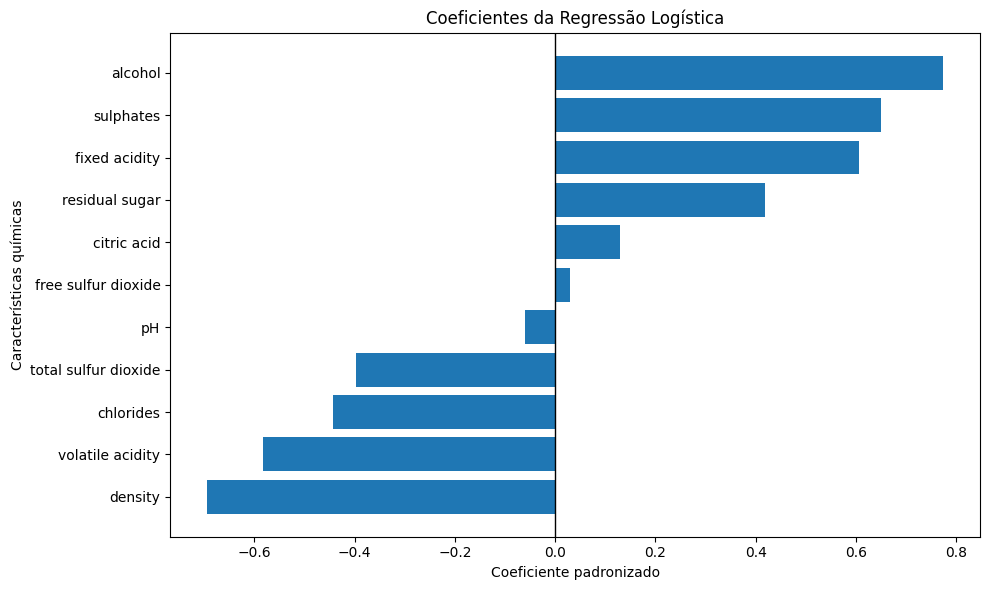

In [21]:

# Organizar as características por coeficiente
importancias_grafico = importancias.sort_values("Coeficiente")

# Criar o gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    importancias_grafico["Caracteristica"],
    importancias_grafico["Coeficiente"]
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Coeficientes da Regressão Logística")
plt.xlabel("Coeficiente padronizado")
plt.ylabel("Características químicas")

plt.tight_layout()

# Salvar para utilizar na apresentação
plt.savefig("importancia_caracteristicas.png", dpi=300)

plt.show()


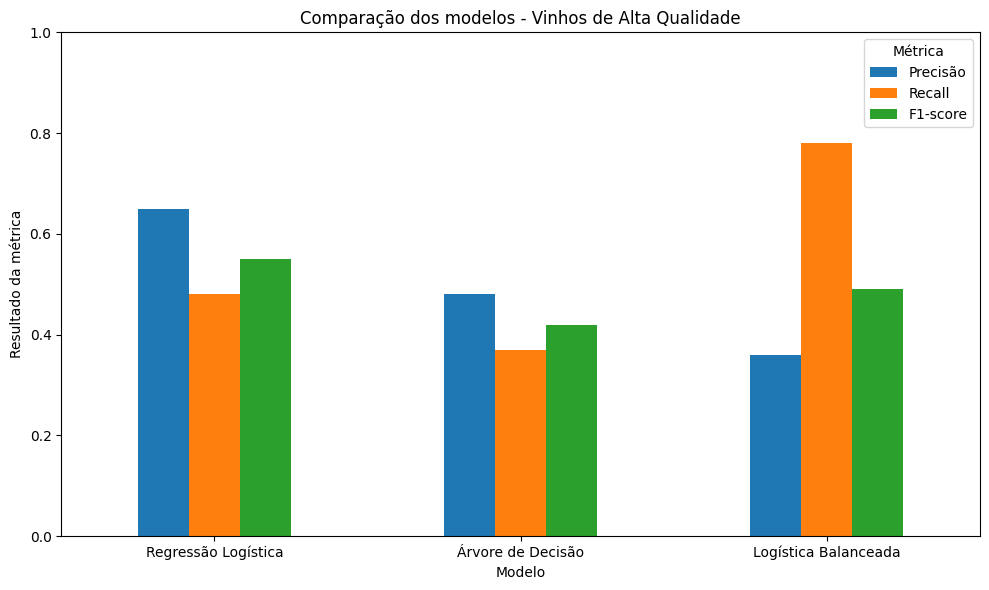

In [22]:
# Resultados dos modelos para a classe 1
comparacao = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Árvore de Decisão",
        "Logística Balanceada"
    ],
    "Precisão": [0.65, 0.48, 0.36],
    "Recall": [0.48, 0.37, 0.78],
    "F1-score": [0.55, 0.42, 0.49]
})

# Organizar os dados para o gráfico
comparacao = comparacao.set_index("Modelo")

# Criar gráfico
comparacao.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparação dos modelos - Vinhos de Alta Qualidade")
plt.ylabel("Resultado da métrica")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Métrica")

plt.tight_layout()

# Salvar gráfico
plt.savefig("comparacao_modelos.png", dpi=300)

plt.show()

## 8. Resultados e comparação dos modelos

Foram avaliados dois algoritmos de classificação: Regressão Logística e Árvore de Decisão. Também foi realizado um experimento adicional com Regressão Logística utilizando balanceamento de classes.

Os dados foram divididos em 80% para treinamento e 20% para teste, mantendo aproximadamente a proporção das classes.

### Comparação dos resultados

| Modelo | Acurácia | Precisão (classe 1) | Recall (classe 1) | F1-score (classe 1) |
|---|---:|---:|---:|---:|
| Regressão Logística | 89,71% | 65% | 48% | 55% |
| Árvore de Decisão | 86,27% | 48% | 37% | 42% |
| Regressão Logística Balanceada | 78,43% | 36% | 78% | 49% |

A Regressão Logística original apresentou a maior acurácia e o melhor F1-score para a classe de alta qualidade.

Entretanto, identificou corretamente apenas 13 dos 27 vinhos de alta qualidade presentes no conjunto de teste.

O modelo balanceado identificou 21 desses 27 vinhos, demonstrando maior capacidade de encontrar amostras da classe minoritária. Em contrapartida, apresentou maior quantidade de falsos positivos.

### Interpretação das características químicas

A análise exploratória indicou associação positiva entre alta qualidade e teor alcoólico, ácido cítrico e sulfatos. A acidez volátil apresentou associação negativa.

Na Regressão Logística, os maiores coeficientes positivos foram observados para teor alcoólico, sulfatos e acidez fixa. Entre os coeficientes negativos mais expressivos estavam densidade e acidez volátil.

Esses resultados indicam características relevantes para as previsões, mas não estabelecem relações de causa e efeito.

## 9. Recomendações para o negócio

Os modelos podem apoiar a triagem inicial de lotes de vinho, utilizando informações obtidas em análises laboratoriais.

Recomenda-se:

- Monitorar características como teor alcoólico, acidez volátil, sulfatos e densidade.
- Utilizar as previsões como apoio à seleção de lotes que merecem avaliação adicional.
- Priorizar o modelo balanceado quando o objetivo for reduzir o risco de deixar passar vinhos potencialmente excelentes.
- Priorizar a Regressão Logística original quando for mais importante reduzir seleções incorretas.
- Manter a avaliação sensorial e os critérios técnicos da vinícola como parte da decisão final.

## 10. Conclusão

O projeto demonstrou que características físico-químicas podem ser utilizadas para desenvolver modelos de classificação da qualidade de vinhos.

A Regressão Logística apresentou o melhor equilíbrio entre precisão e recall para a classe de alta qualidade, enquanto sua versão balanceada identificou uma proporção maior dos vinhos dessa categoria.

O desbalanceamento dos dados mostrou-se um desafio importante, reforçando a necessidade de avaliar diferentes métricas, e não apenas a acurácia.

Como limitação, os resultados foram obtidos em uma única base de dados e ainda precisam de validação em novas amostras antes de uma eventual aplicação operacional.

Como próximos passos, recomenda-se avaliar outros algoritmos, ajustar seus parâmetros e testar o desempenho em dados independentes.